# Annex — Which opening families behave alike?
## Complement to C2_clustering.ipynb, same route (clustering)

**Group 03:** Javier Alcaíno, Lucas Riquelme and Renato Varela.

This notebook is an **optional annex** that complements `C2_clustering.ipynb`, not a second
certamen or a second route. `C2_clustering.ipynb` grouped **games** (player-game
perspective) and found that the groups end up dominated by speed and rating, adding little
about specific openings — something already discussed when reviewing those results:
grouping games is not the most direct way to answer "which openings behave alike, so they
can be grouped into the same study material?".

This annex changes the **unit of analysis**: instead of one row per game, **one row is one
opening family** (from those observed in `opening_family_20`), described by how it behaves
in the games where it appears. This is still clustering — we are just grouping openings,
not players.


## 1. Why this is closer to what the coordinator actually needs

The coordinator does not decide "which group does this game fall into" — they decide
**which openings to group into the same review material**. Grouping openings directly by
their observed behaviour (not by their name or tactical family) answers that question much
more directly.

**A warning that applies even more strongly here than in the main notebook:** if two
openings land in the same group because they show a similar score pattern, that **does
not** mean those openings are "equally good," nor that one is better than the other. The
pool of players who choose each opening is not random — players of a certain level or style
tend to prefer certain openings. If an opening appears in a lower-scoring group, that is a
**signal of where to look more closely** (review those specific games), not a conclusion
about whether that opening "works." The observed difference could be entirely explained by
who plays it, not by the opening itself — exactly the same underlying problem that prevents
any causal claim throughout this whole project.


In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score

def find_root():
    here = Path.cwd().resolve()
    candidates = [here, *here.parents, here / "GROUP_03_Chess"]
    return next(p for p in candidates if (p / "provenance/source_manifest.json").exists())

ROOT = find_root()
TABLES = ROOT / "outputs/tables"
FIGURES = ROOT / "outputs/figures"
contract = json.loads((ROOT / "provenance/W2_frozen_contract.json").read_text())
SEED = contract["seed"]
MIN_OPENING_GAMES = 100  # minimum July games for an opening's profile to be trustworthy

pd.set_option("display.max_columns", 15)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 160, "axes.spines.top": False,
                     "axes.spines.right": False, "font.family": "DejaVu Sans"})

def save_figure(name):
    plt.savefig(FIGURES / name, bbox_inches="tight", facecolor="white")
    plt.show()

train = pd.read_csv(ROOT / "data/splits/train.csv")
validation = pd.read_csv(ROOT / "data/splits/validation.csv")
test = pd.read_csv(ROOT / "data/splits/test.csv")
print(f"Loaded train (July)={len(train):,}, validation (August)={len(validation):,}, "
      f"test (September)={len(test):,} games. Minimum games per opening: {MIN_OPENING_GAMES}.")


Matplotlib is building the font cache; this may take a moment.


Loaded train (July)=30,615, validation (August)=25,782, test (September)=30,553 games. Minimum games per opening: 100.


## 2. Building one profile per opening family from unique July games

Each game contributes one opening label from its shared White-and-Black move sequence.
The White-oriented profile has five features: White score rate, draw share, mean White
player rating (`mean_white_rating`, in Lichess rating points), Blitz share and Pearson
correlation of White rating with White score within the family. Black's score in each
game is the complement and does not add a separate opening observation.

July fit profiles require at least 100 games per family. Score and draw shares describe
past games in each profile. The annex groups historical outcomes and does not evaluate
prediction at ply 20.


In [2]:
def opening_profile(games):
    white_score = games.outcome.map({"white_win": 1.0, "draw": 0.5, "black_win": 0.0})
    g = games.assign(white_score=white_score).groupby("opening_family_20", observed=True)

    def _agg(sub):
        n = len(sub)
        out = {
            "n_games": n,
            "score_rate_white": sub.white_score.mean(),
            "draw_rate": (sub.outcome == "draw").mean(),
            "mean_white_rating": sub.white_rating.mean(),
            "pct_blitz": (sub.speed == "blitz").mean(),
        }
        out["rating_score_corr"] = (sub.white_rating.corr(sub.white_score)
                                     if n >= 30 and sub.white_rating.std() > 0 else np.nan)
        return pd.Series(out)

    return g.apply(_agg, include_groups=False).reset_index()

FEATURES = ["score_rate_white", "draw_rate", "mean_white_rating", "pct_blitz", "rating_score_corr"]

profile_jul = opening_profile(train)
profile_jul_fit = profile_jul[profile_jul.n_games >= MIN_OPENING_GAMES].reset_index(drop=True)
print(f"{len(profile_jul_fit)} of {len(profile_jul)} opening families in July reach "
      f">= {MIN_OPENING_GAMES} games (covering "
      f"{profile_jul_fit.n_games.sum() / profile_jul.n_games.sum():.1%} of July games).")
print(profile_jul_fit.sort_values("n_games", ascending=False).head(8).round(3).to_string(index=False))


46 of 137 opening families in July reach >= 100 games (covering 92.8% of July games).
   opening_family_20   n_games  score_rate_white  draw_rate  mean_white_rating  pct_blitz  rating_score_corr
    Sicilian Defense 3,267.000             0.496      0.039          1,699.750      0.775              0.063
   Queen's Pawn Game 3,113.000             0.519      0.042          1,524.072      0.758              0.015
      French Defense 1,888.000             0.507      0.043          1,626.151      0.789              0.001
   Caro-Kann Defense 1,816.000             0.505      0.041          1,609.907      0.741              0.031
Scandinavian Defense 1,501.000             0.473      0.051          1,515.650      0.747             -0.014
        Italian Game 1,491.000             0.526      0.048          1,477.313      0.657              0.015
    King's Pawn Game   955.000             0.519      0.038          1,328.351      0.672              0.029
     English Opening   927.000            

## 3. Standardize and reduce with PCA

The scaler and three-component PCA are fit on July family profiles. The scatterplot shows two of those components.

In [3]:
scaler = StandardScaler().fit(profile_jul_fit[FEATURES])
X_jul = scaler.transform(profile_jul_fit[FEATURES])
pca = PCA(n_components=3, random_state=SEED).fit(X_jul)
Xp_jul = pca.transform(X_jul)
print("Explained variance per component:", pca.explained_variance_ratio_.round(3))
print("Cumulative explained variance:", pca.explained_variance_ratio_.cumsum().round(3))
print("Loadings of the first 2 components:")
print(pd.DataFrame(pca.components_[:2].T, index=FEATURES, columns=["PC1", "PC2"]).round(3))


Explained variance per component: [0.357 0.247 0.207]
Cumulative explained variance: [0.357 0.604 0.812]
Loadings of the first 2 components:
                     PC1    PC2
score_rate_white  -0.204  0.592
draw_rate         -0.098  0.742
mean_white_rating  0.677  0.214
pct_blitz          0.699  0.060
rating_score_corr -0.030 -0.222


## 4. Choosing K with a Gaussian Mixture Model (GMM)

The main notebook used k-prototypes (mixed-type data). Here, with numeric-only variables,
we use a **Gaussian Mixture Model (GMM)** — the same alternative to K-means the
unsupervised-models class presents for when group membership can be uncertain or
overlapping. We choose K with the **BIC** (Bayesian Information Criterion, as taught in
class): smaller values are preferred within the tested K = 2–6 range.
The original grid started at two, so it cannot compare the mixture with a single component.


 K     BIC  silhouette                sizes
 2 477.878       0.253             [16, 30]
 3 493.029       0.223          [7, 24, 15]
 4 518.412       0.239      [15, 10, 16, 5]
 5 516.250       0.192   [11, 14, 12, 8, 1]
 6 523.149       0.280 [3, 14, 6, 1, 9, 13]


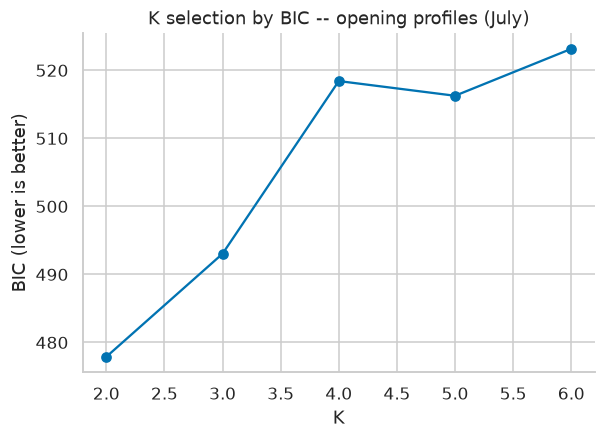


Chosen K = 2 (lowest BIC). Groups with a single member at larger K (e.g. K=6) are not evidence of better structure -- they are overfitting with few data points (only 46 openings in total).


In [4]:
bic_rows = []
for k in range(2, 7):
    gm_k = GaussianMixture(n_components=k, random_state=SEED, n_init=10).fit(Xp_jul)
    labels_k = gm_k.predict(Xp_jul)
    sizes = pd.Series(labels_k).value_counts().sort_index().tolist()
    sil = silhouette_score(Xp_jul, labels_k) if len(set(labels_k)) > 1 else np.nan
    bic_rows.append({"K": k, "BIC": gm_k.bic(Xp_jul), "silhouette": sil, "sizes": sizes})

bic_table = pd.DataFrame(bic_rows)
bic_table.to_csv(TABLES / "C2_anexo_bic_selection.csv", index=False)
print(bic_table.round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(bic_table.K, bic_table.BIC, "o-")
ax.set_xlabel("K"); ax.set_ylabel("BIC (lower is better)")
ax.set_title("K selection by BIC -- opening profiles (July)")
save_figure("C2_anexo_01_bic.png")

K_CHOSEN = int(bic_table.loc[bic_table.BIC.idxmin(), "K"])
print(f"\nChosen K = {K_CHOSEN} (lowest BIC). Groups with a single member at larger K "
      f"(e.g. K=6) are not evidence of better structure -- they are overfitting with few "
      f"data points (only {len(profile_jul_fit)} openings in total).")


## 5. Opening-group profiles (July)

**Records used:** the 46 opening families with at least 100 games in July. **Variables
used:** the 5 described in Section 2. Conclusions are limited to these families -- low-
frequency openings are excluded for lack of sufficient evidence, not because they are
assumed not to matter.


         score_rate_white  draw_rate  mean_white_rating  pct_blitz  rating_score_corr  n_games  n_openings
cluster                                                                                                   
0                   0.533      0.048          1,453.539      0.691              0.025  652.688          16
1                   0.506      0.043          1,631.972      0.778              0.017  598.567          30

Group 0 (16 openings): Bishop's Opening, Center Game, Four Knights Game, Italian Game, King's Knight Opening, King's Pawn Game, Nimzowitsch Defense, Petrov's Defense, Ponziani Opening, Queen's Gambit Accepted, Queen's Pawn Game, Ruy Lopez, Scotch Game, Three Knights Opening, Van't Kruijs Opening, Vienna Game
Group 1 (30 openings): Alekhine Defense, Benoni Defense, Bird Opening, Caro-Kann Defense, Dutch Defense, English Defense, English Opening, Englund Gambit, Englund Gambit Declined, French Defense, Horwitz Defense, Hungarian Opening, Indian Defense, King's Gambit

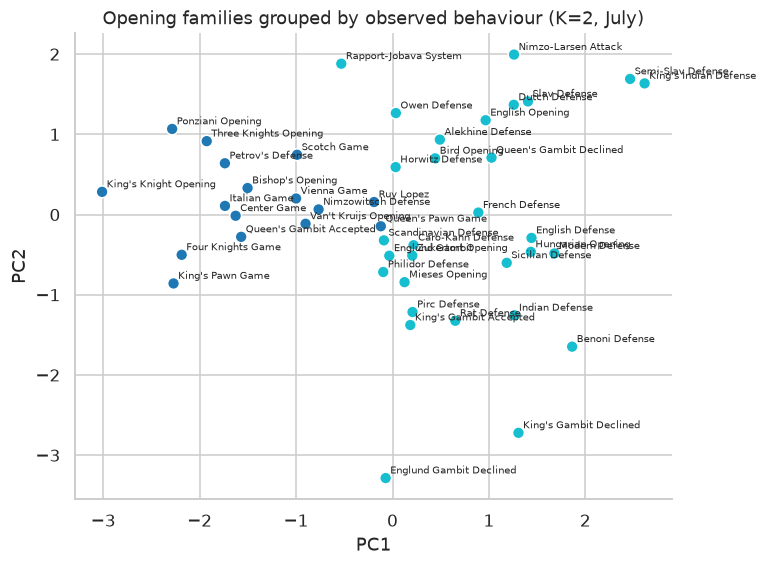

In [5]:
gm = GaussianMixture(n_components=K_CHOSEN, random_state=SEED, n_init=10).fit(Xp_jul)
profile_jul_fit = profile_jul_fit.assign(cluster=gm.predict(Xp_jul))

cluster_summary = profile_jul_fit.groupby("cluster")[FEATURES + ["n_games"]].mean().round(3)
cluster_summary["n_openings"] = profile_jul_fit.groupby("cluster").size()
print(cluster_summary.to_string())
print()

for c in sorted(profile_jul_fit.cluster.unique()):
    names = profile_jul_fit.loc[profile_jul_fit.cluster == c, "opening_family_20"].tolist()
    print(f"Group {c} ({len(names)} openings): {', '.join(sorted(names))}")

profile_jul_fit.to_csv(TABLES / "C2_anexo_opening_clusters_july.csv", index=False)

fig, ax = plt.subplots(figsize=(7, 5.5))
scatter = ax.scatter(Xp_jul[:, 0], Xp_jul[:, 1], c=profile_jul_fit.cluster, cmap="tab10",
                      s=60, edgecolor="white")
for i, row in profile_jul_fit.iterrows():
    ax.annotate(row.opening_family_20, (Xp_jul[i, 0], Xp_jul[i, 1]), fontsize=6.5,
                xytext=(3, 3), textcoords="offset points")
ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
ax.set_title(f"Opening families grouped by observed behaviour (K={K_CHOSEN}, July)")
save_figure("C2_anexo_02_opening_clusters.png")


## 6. Comparison with the simple rule already used in C1

C1 already built a "training agenda" (`C1_training_agenda.csv`) using a deliberately simple
rule: pick the **most frequent** opening within each colour×speed×level cell, with no model
involved. We check whether grouping by behaviour (this annex) distinguishes something that
the frequency rule, on its own, does not.


In [6]:
freq_rank = profile_jul_fit.sort_values("n_games", ascending=False).reset_index(drop=True)
top_by_frequency = freq_rank.head(K_CHOSEN + 2)[["opening_family_20", "n_games", "cluster"]]
print("Most frequent openings in July (C1's simple rule) and which behaviour group they "
      "belong to:")
print(top_by_frequency.to_string(index=False))

n_clusters_among_top = top_by_frequency.cluster.nunique()
print(f"\nThe {len(top_by_frequency)} most frequent openings fall into {n_clusters_among_top} "
      f"distinct behaviour group(s) (out of {K_CHOSEN} possible). "
      + ("This suggests the frequency rule on its own mixes openings with different "
         "profiles into the same review package -- grouping by behaviour does add "
         "something frequency alone does not see." if n_clusters_among_top > 1 else
         "In this case the most frequent openings turned out fairly similar in "
         "behaviour, so the simple rule would already have treated them alike."))


Most frequent openings in July (C1's simple rule) and which behaviour group they belong to:
opening_family_20   n_games  cluster
 Sicilian Defense 3,267.000        1
Queen's Pawn Game 3,113.000        0
   French Defense 1,888.000        1
Caro-Kann Defense 1,816.000        1

The 4 most frequent openings fall into 2 distinct behaviour group(s) (out of 2 possible). This suggests the frequency rule on its own mixes openings with different profiles into the same review package -- grouping by behaviour does add something frequency alone does not see.


## 7. Assignment sensitivity across source windows

For each later window, recompute the profiles for July's selected families and apply the
July scaler, PCA and mixture. Every July family is included in the denominator; a missing
assignment counts as nonmatching. The July threshold is a fit criterion, so later families
may use fewer than 100 games. Missing feature values are filled with the July feature mean.
The summary reports coverage and support so the assignment agreement can be read with
that caveat.


In [7]:
def assign_other_month(games, month_label):
    prof = opening_profile(games)
    prof = prof[prof.opening_family_20.isin(profile_jul_fit.opening_family_20)].reset_index(drop=True)
    X = scaler.transform(prof[FEATURES].fillna(profile_jul_fit[FEATURES].mean()))
    Xp = pca.transform(X)
    prof[f"cluster_{month_label}"] = gm.predict(Xp)
    return prof[["opening_family_20", "n_games", f"cluster_{month_label}"]].rename(
        columns={"n_games": f"n_games_{month_label}"})

aug_assign = assign_other_month(validation, "aug")
sep_assign = assign_other_month(test, "sep")

stability = profile_jul_fit[["opening_family_20", "cluster", "n_games"]].rename(
    columns={"cluster": "cluster_jul", "n_games": "n_games_jul"})
stability = stability.merge(aug_assign, on="opening_family_20", how="left")
stability = stability.merge(sep_assign, on="opening_family_20", how="left")
stability["stable_jul_aug"] = stability.cluster_jul == stability.cluster_aug
stability["stable_jul_sep"] = stability.cluster_jul == stability.cluster_sep
stability.to_csv(TABLES / "C2_anexo_month_stability.csv", index=False)

print(f"Openings whose group stays the same between July and August: "
      f"{stability.stable_jul_aug.mean():.1%} ({stability.stable_jul_aug.sum()}/{len(stability)})")
print(f"Openings whose group stays the same between July and September: "
      f"{stability.stable_jul_sep.mean():.1%} ({stability.stable_jul_sep.sum()}/{len(stability)})")
print(stability[["n_games_aug", "n_games_sep"]].agg(["count", "min", "median"]).to_string())
print("Families with fewer than 100 games:",
      stability[["n_games_aug", "n_games_sep"]].lt(MIN_OPENING_GAMES).sum().to_dict())
print()
print("Openings that DID change group in some month (review with more caution):")
changed = stability[~(stability.stable_jul_aug & stability.stable_jul_sep)]
print(changed[["opening_family_20", "cluster_jul", "cluster_aug", "cluster_sep"]].to_string(index=False))


Openings whose group stays the same between July and August: 87.0% (40/46)
Openings whose group stays the same between July and September: 87.0% (40/46)
        n_games_aug  n_games_sep
count        46.000       46.000
min          99.000      113.000
median      300.000      367.500
Families with fewer than 100 games: {'n_games_aug': 1, 'n_games_sep': 0}

Openings that DID change group in some month (review with more caution):
      opening_family_20  cluster_jul  cluster_aug  cluster_sep
            Center Game            0            1            0
  King's Knight Opening            0            1            0
    Nimzowitsch Defense            0            1            1
       Philidor Defense            1            0            0
           Pirc Defense            1            0            1
Queen's Gambit Accepted            0            0            1
  Rapport-Jobava System            1            1            0
   Scandinavian Defense            1            1            0
 

## 8. Interpretation

Of 137 July families, 46 reach 100 games and cover 92.8% of July games. BIC favors K = 2
(477.9) among K = 2–6. The two groups have 16 and 30 families. Their means are calculated
across family profiles, giving each selected family equal weight. The mean White player
ratings across those profiles are about 1,454 and 1,632. White's mean score rates are
53.3% and 50.6%, and mean Blitz shares are 69.1% and 77.8%.

The four most frequent July families occupy both groups. Frequency measures exposure
while the annex summarizes co-occurring profile characteristics. Whether grouping
training material this way improves a session is a separate question.

Forty of 46 families receive the same assignment in July and August, and 40 of 46 in
July and September (87.0% in each comparison). Thirty-seven agree in all three windows.
Short windows and varying support limit how broadly to read that agreement. This annex
is complementary. The [C3 review decision](C3_final_visualizations.ipynb) comes from
the September manual segment and observed losses, independently of the annex.


## AI-use note and references

This annex was designed and implemented with support from Claude Code (Anthropic) --
variable selection, profiling/PCA/GMM code, and drafting of the interpretation -- under the
team's direct supervision; every number comes from this notebook's actual execution.

**Additional references, beyond those already cited in `C2_clustering.ipynb`:**

1. Schwarz, G. (1978). *Estimating the Dimension of a Model* (the BIC criterion).
2. Course material: `06_.../BI_Trimestral_Unsupervised_Models_Masterclass.ipynb`, the
   Gaussian Mixture Models and BIC-based component selection section.
3. `outputs/tables/C1_training_agenda.csv` -- C1's frequency rule, used as the simple
   reference in Section 6.
